# Student Performance Prediction - Learning Notebook
Run the cells **from top to bottom**. Each section matches a step in `TUTORIAL.md`.
Read the explanation, guess what the output will be, *then* run the cell.

In [1]:
import sys
sys.path.append("..")          # lets the notebook import our own code from src/

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *
from src.data_cleaning import clean_data
from src.features import add_features, build_pipeline, ALL_FEATURES
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

## Step 4 - Load and inspect the raw data
We always look at data *before* modelling. Real data is messy.

In [2]:
df_raw = pd.read_csv(RAW_DATA_PATH)
df_raw.head()

,student_id,study_hours,attendance,previous_score,assignment_score,internal_score,sleep_hours,class_participation,previous_failed_subjects,result
0,783,7.8,84.8,75.6,73.6,NaN,7.1,Medium,0.0,Pass
1,77,3.5,74.5,49.7,80.2,58.4,5.6,Low,1.0,Fail
2,1010,4.0,90.4,NaN,NaN,65.3,7.6,Medium,0.0,Fail
3,1404,2.6,86.4,57.2,52.9,63.7,5.2,High,1.0,Pass
4,847,7.6,100.0,90.7,95.1,84.5,8.2,High,0.0,Pass


In [3]:
print("Shape (rows, columns):", df_raw.shape)
print()
print(df_raw.dtypes)

Shape (rows, columns): (1525, 10)

student_id                    int64
study_hours                 float64
attendance                  float64
previous_score              float64
assignment_score            float64
internal_score              float64
sleep_hours                 float64
class_participation             str
previous_failed_subjects    float64
result                          str
dtype: object


In [4]:
print("Missing values per column:")
print(df_raw.isnull().sum())
print()
print("Duplicate rows:", df_raw.duplicated().sum())

Missing values per column:
student_id                   0
study_hours                 52
attendance                  56
previous_score              53
assignment_score            53
internal_score              52
sleep_hours                 53
class_participation         50
previous_failed_subjects    53
result                       0
dtype: int64

Duplicate rows: 25


In [5]:
df_raw.describe().round(2)

,student_id,study_hours,attendance,previous_score,assignment_score,internal_score,sleep_hours,previous_failed_subjects
count,1525.00,1473.00,1469.00,1472.00,1472.00,1473.00,1472.00,1472.00
mean,752.96,3.93,77.98,61.74,65.74,63.96,6.81,1.06
std,433.73,1.94,11.16,14.65,13.64,15.07,1.44,1.19
min,1.00,-3.00,38.80,18.10,19.60,23.60,3.50,0.00
25%,379.00,2.60,70.40,51.08,56.60,53.80,6.00,0.00
50%,753.00,3.90,77.90,62.00,65.75,63.90,6.70,1.00
75%,1129.00,5.20,85.30,72.40,75.30,73.50,7.50,2.00
max,1500.00,10.70,120.00,100.00,100.00,150.00,24.00,6.00


**Look at `min` and `max`.** `study_hours` has a minimum of **-3** (impossible), `sleep_hours` has a maximum of **24**, and
some scores go above 100. Those are data-entry errors we must fix.

In [6]:
print(df_raw["result"].value_counts())
print()
print(df_raw["result"].value_counts(normalize=True).round(3))
df_raw["class_participation"].value_counts(dropna=False)

result
Pass    866
Fail    659
Name: count, dtype: int64

result
Pass    0.568
Fail    0.432
Name: proportion, dtype: float64


class_participation
Low          513
Medium       477
High         445
NaN           50
  Medium      15
high          15
LOW           10
Name: count, dtype: int64

The target is reasonably balanced (about 57% Pass / 43% Fail), so plain accuracy is not misleading here.
Notice the participation column has messy labels: `high`, `  Medium `, `LOW`.

## Step 5 - Clean the data
Open `src/data_cleaning.py` and read `clean_data()` next to this cell.

In [7]:
df = clean_data(df_raw)
print("Rows before:", len(df_raw), "| Rows after:", len(df))
print()
print(df["class_participation"].value_counts(dropna=False))
print()
df.describe().round(2).loc[["min", "max"]]

Duplicates removed: 25
Incorrect values in 'study_hours' set to missing: 5
Incorrect values in 'attendance' set to missing: 6
Incorrect values in 'internal_score' set to missing: 5
Incorrect values in 'sleep_hours' set to missing: 4
Rows before: 1525 | Rows after: 1500

class_participation
Low       511
Medium    490
High      450
NaN        49
Name: count, dtype: int64



,student_id,study_hours,attendance,previous_score,assignment_score,internal_score,sleep_hours,previous_failed_subjects,result
min,1.0,0.0,38.8,18.1,19.6,23.6,3.5,0.0,0.0
max,1500.0,10.7,100.0,100.0,100.0,100.0,10.0,6.0,1.0


Duplicates are gone, labels are consistent, and impossible values became **missing** (NaN).
We do **not** fill the missing values yet. Filling uses statistics (the median) learned from data, so it must happen
*after* the train/test split, otherwise test information leaks into training.

## Step 6 - Exploratory Data Analysis

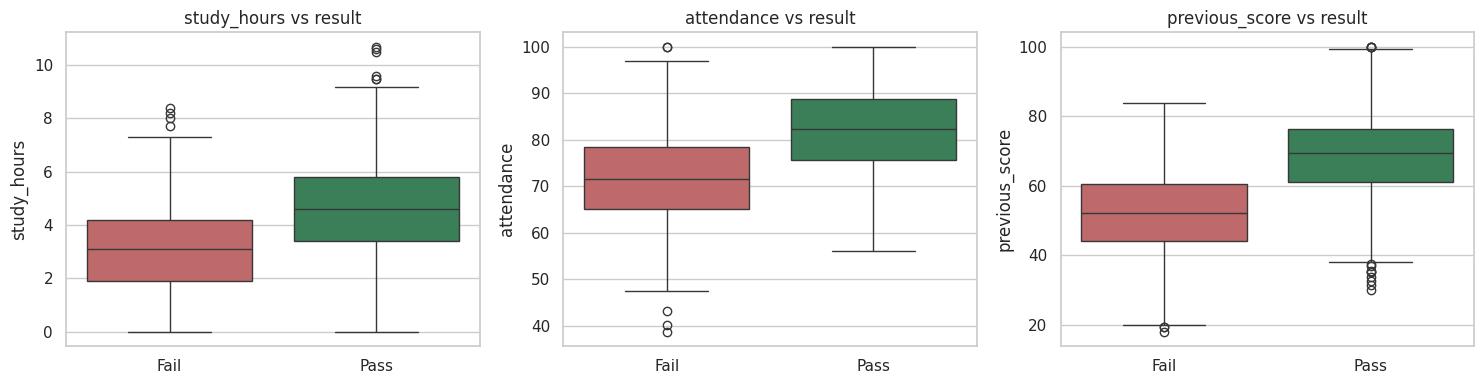

In [8]:
df["result_label"] = df[TARGET].map({1: "Pass", 0: "Fail"})
palette = {"Pass": "seagreen", "Fail": "indianred"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["study_hours", "attendance", "previous_score"]):
    sns.boxplot(data=df, x="result_label", y=col, hue="result_label", palette=palette,
                order=["Fail", "Pass"], legend=False, ax=ax)
    ax.set_title(f"{col} vs result"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Insight:** the *Pass* box sits clearly higher for all three features. Students who study more, attend more and scored
higher before tend to pass. The boxes overlap a bit, which is why no model will be 100% accurate.

class_participation
Low       29.9
Medium    60.8
High      83.3
Name: result, dtype: float64


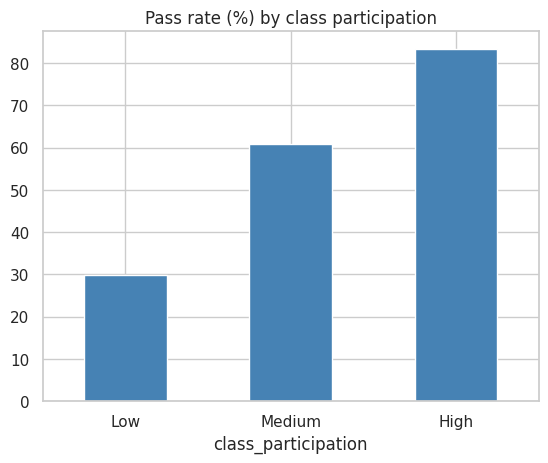

In [9]:
pass_rate = df.groupby("class_participation")[TARGET].mean().reindex(PARTICIPATION_ORDER) * 100
print(pass_rate.round(1))
pass_rate.plot(kind="bar", color="steelblue", title="Pass rate (%) by class participation", rot=0)
plt.show()

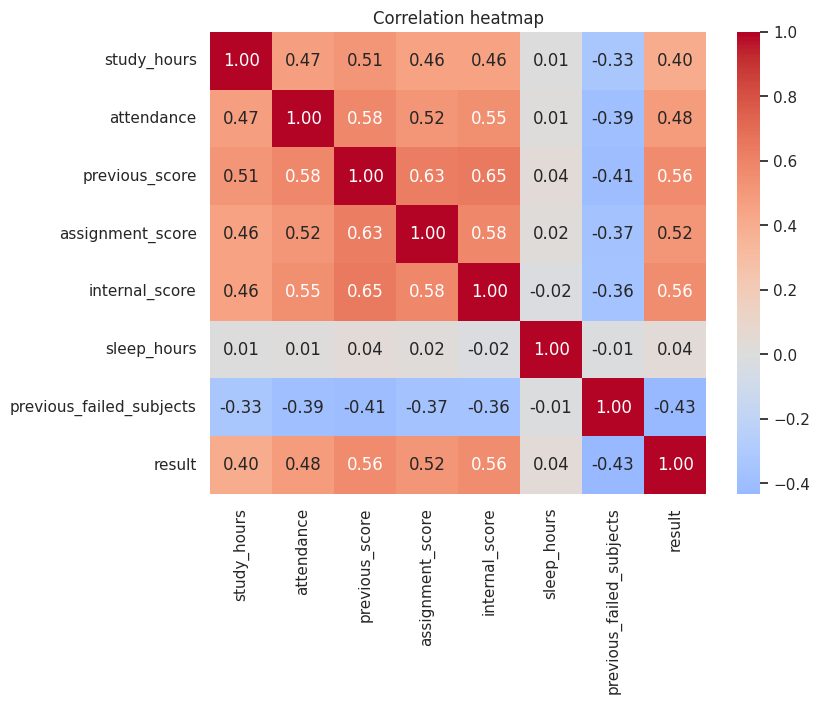

In [10]:
plt.figure(figsize=(8, 6))
corr = df[NUMERIC_FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()

**Insight:** `previous_score`, `internal_score` and `assignment_score` have the strongest link with passing.
`previous_failed_subjects` is **negative** (more past failures, lower chance of passing).
`sleep_hours` has almost **no linear link** here. A model may still use it a little, but do not expect much.

## Step 7 - Feature engineering

In [11]:
preview = add_features(df[ALL_FEATURES[:7] + ["class_participation"]])
preview[["previous_score", "assignment_score", "internal_score", "avg_academic_score",
         "previous_failed_subjects", "has_failed_before", "attendance", "low_attendance"]].head(8)

,previous_score,assignment_score,internal_score,avg_academic_score,previous_failed_subjects,has_failed_before,attendance,low_attendance
0,75.6,73.6,NaN,74.600000,0.0,0.0,84.8,0.0
1,49.7,80.2,58.4,62.766667,1.0,1.0,74.5,1.0
2,NaN,NaN,65.3,65.300000,0.0,0.0,90.4,0.0
3,57.2,52.9,63.7,57.933333,1.0,1.0,86.4,0.0
4,90.7,95.1,84.5,90.100000,0.0,0.0,100.0,0.0
5,76.0,74.2,76.1,75.433333,0.0,0.0,89.3,0.0
6,NaN,46.7,56.0,51.350000,4.0,1.0,69.3,1.0
7,37.0,68.5,59.9,55.133333,3.0,1.0,58.2,1.0


We created 3 new columns from existing ones: **avg_academic_score** (one summary of overall ability),
**has_failed_before** (yes/no) and **low_attendance** (below the 75% rule).

## Step 8 - Train-test split

In [12]:
from sklearn.model_selection import train_test_split

X = df[[c for c in ALL_FEATURES if c in df.columns]]   # features (inputs)
y = df[TARGET]                                          # target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Pass share in train:", round(y_train.mean(), 3), "| in test:", round(y_test.mean(), 3))

Training set: (1200, 8) | Test set: (300, 8)
Pass share in train: 0.568 | in test: 0.57


## Step 9 - Train the three models

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE),
}
fitted = {}
for name, model in models.items():
    pipe = build_pipeline(model)
    pipe.fit(X_train, y_train)        # <- this one line is the "learning"
    fitted[name] = pipe
    print("Trained:", name)

Trained: Logistic Regression
Trained: Decision Tree


Trained: Random Forest


## Step 10 - Evaluate

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

rows = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1-score": f1_score(y_test, pred)})
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.830,0.870,0.825,0.847
Decision Tree,0.810,0.896,0.754,0.819
Random Forest,0.827,0.852,0.842,0.847


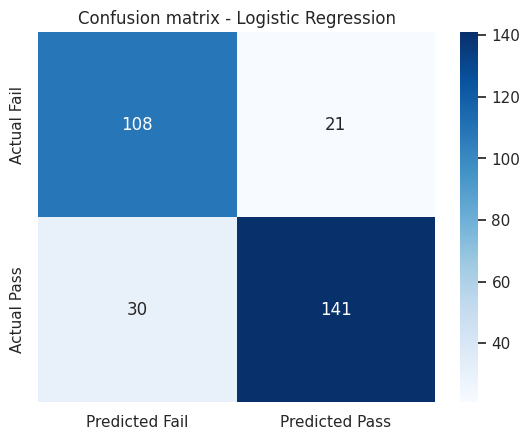

In [15]:
best = fitted["Logistic Regression"]
cm = confusion_matrix(y_test, best.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Fail", "Predicted Pass"], yticklabels=["Actual Fail", "Actual Pass"])
plt.title("Confusion matrix - Logistic Regression"); plt.show()

Read the matrix: top-left = failing students correctly flagged, bottom-right = passing students correctly identified.
The other two boxes are mistakes. Full explanation in `TUTORIAL.md`, Step 10.

## Step 11 - Look inside the winning model
Logistic Regression gives each feature a **coefficient**. Bigger absolute value means a stronger influence.

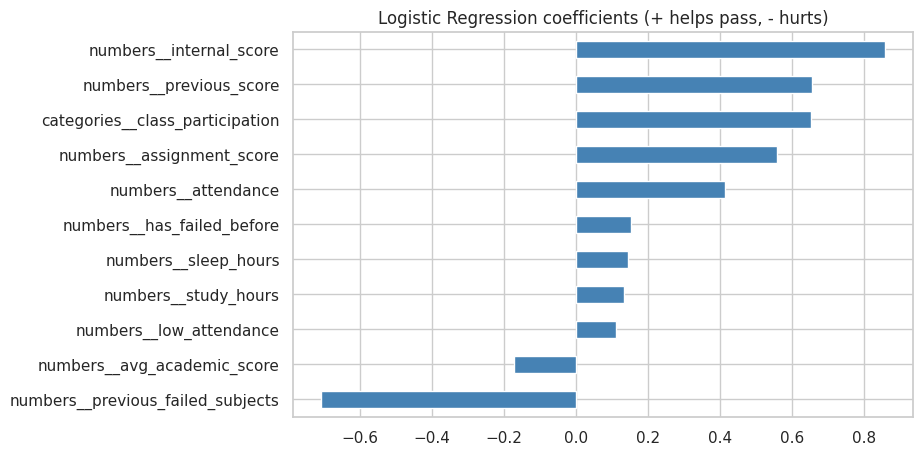

In [16]:
lr_pipeline = fitted["Logistic Regression"]
feature_names = lr_pipeline.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(lr_pipeline.named_steps["model"].coef_[0], index=feature_names)
coefficients.sort_values().plot(kind="barh", color="steelblue", figsize=(8, 5),
                                title="Logistic Regression coefficients (+ helps pass, - hurts)")
plt.show()

Features are strongly related to each other (e.g. all three scores), so individual coefficients should be read as a rough guide only,
not as exact cause-and-effect.